# 8. The models: description and comparison

Three stand-in models rate the attributed texts of the toy data: one that follows the tone, one that is harsher, and one that takes the opposite side.

In [1]:
import tempfile
from pathlib import Path

import pandas as pd

from perspective_audit import annotate, load_model_inputs, run_dataset, save_au_tables
from perspective_audit.toy import toy_ratings, toy_spec

pd.set_option("display.width", 160)
result = run_dataset(toy_spec(), raw=toy_ratings())                      # the toy dataset
out = Path(tempfile.mkdtemp())                                           # where the runs are saved
save_au_tables({"toy": result.au}, out)                                  # aposteriori_for_models.csv: the attributed texts
inputs = load_model_inputs(out / "aposteriori_for_models.csv")
WORD = {"toy": "comment"}                                                # how a text is called in a prompt

In [2]:
from perspective_audit.toy import standin_model

MODELS = ["calm", "harsh", "contrarian"]
for name in MODELS:
    annotate(standin_model(name, mode=name), inputs, out, prompt=lambda texts, item: f"Rate each {item} from 1 to 5:\n{texts}", run="baseline", item_words=WORD, show_progress=False)

## How each model uses the scale

In [3]:
from perspective_audit import model_eda

tables = model_eda(out, datasets=["toy"], models=MODELS)
tables["scores"].pivot(index="score", columns="model", values="share_pct")[MODELS]

model,calm,harsh,contrarian
score,,,
1,50.0,0.0,50.0
2,0.0,0.0,0.0
3,0.0,50.0,0.0
4,0.0,0.0,0.0
5,50.0,50.0,50.0


## Civil and toxic labels

In [4]:
tables["labels"]

,model,civil,toxic,civil_pct,toxic_pct
0,calm,20,20,50.0,50.0
1,harsh,0,40,0.0,100.0
2,contrarian,20,20,50.0,50.0


## The figures

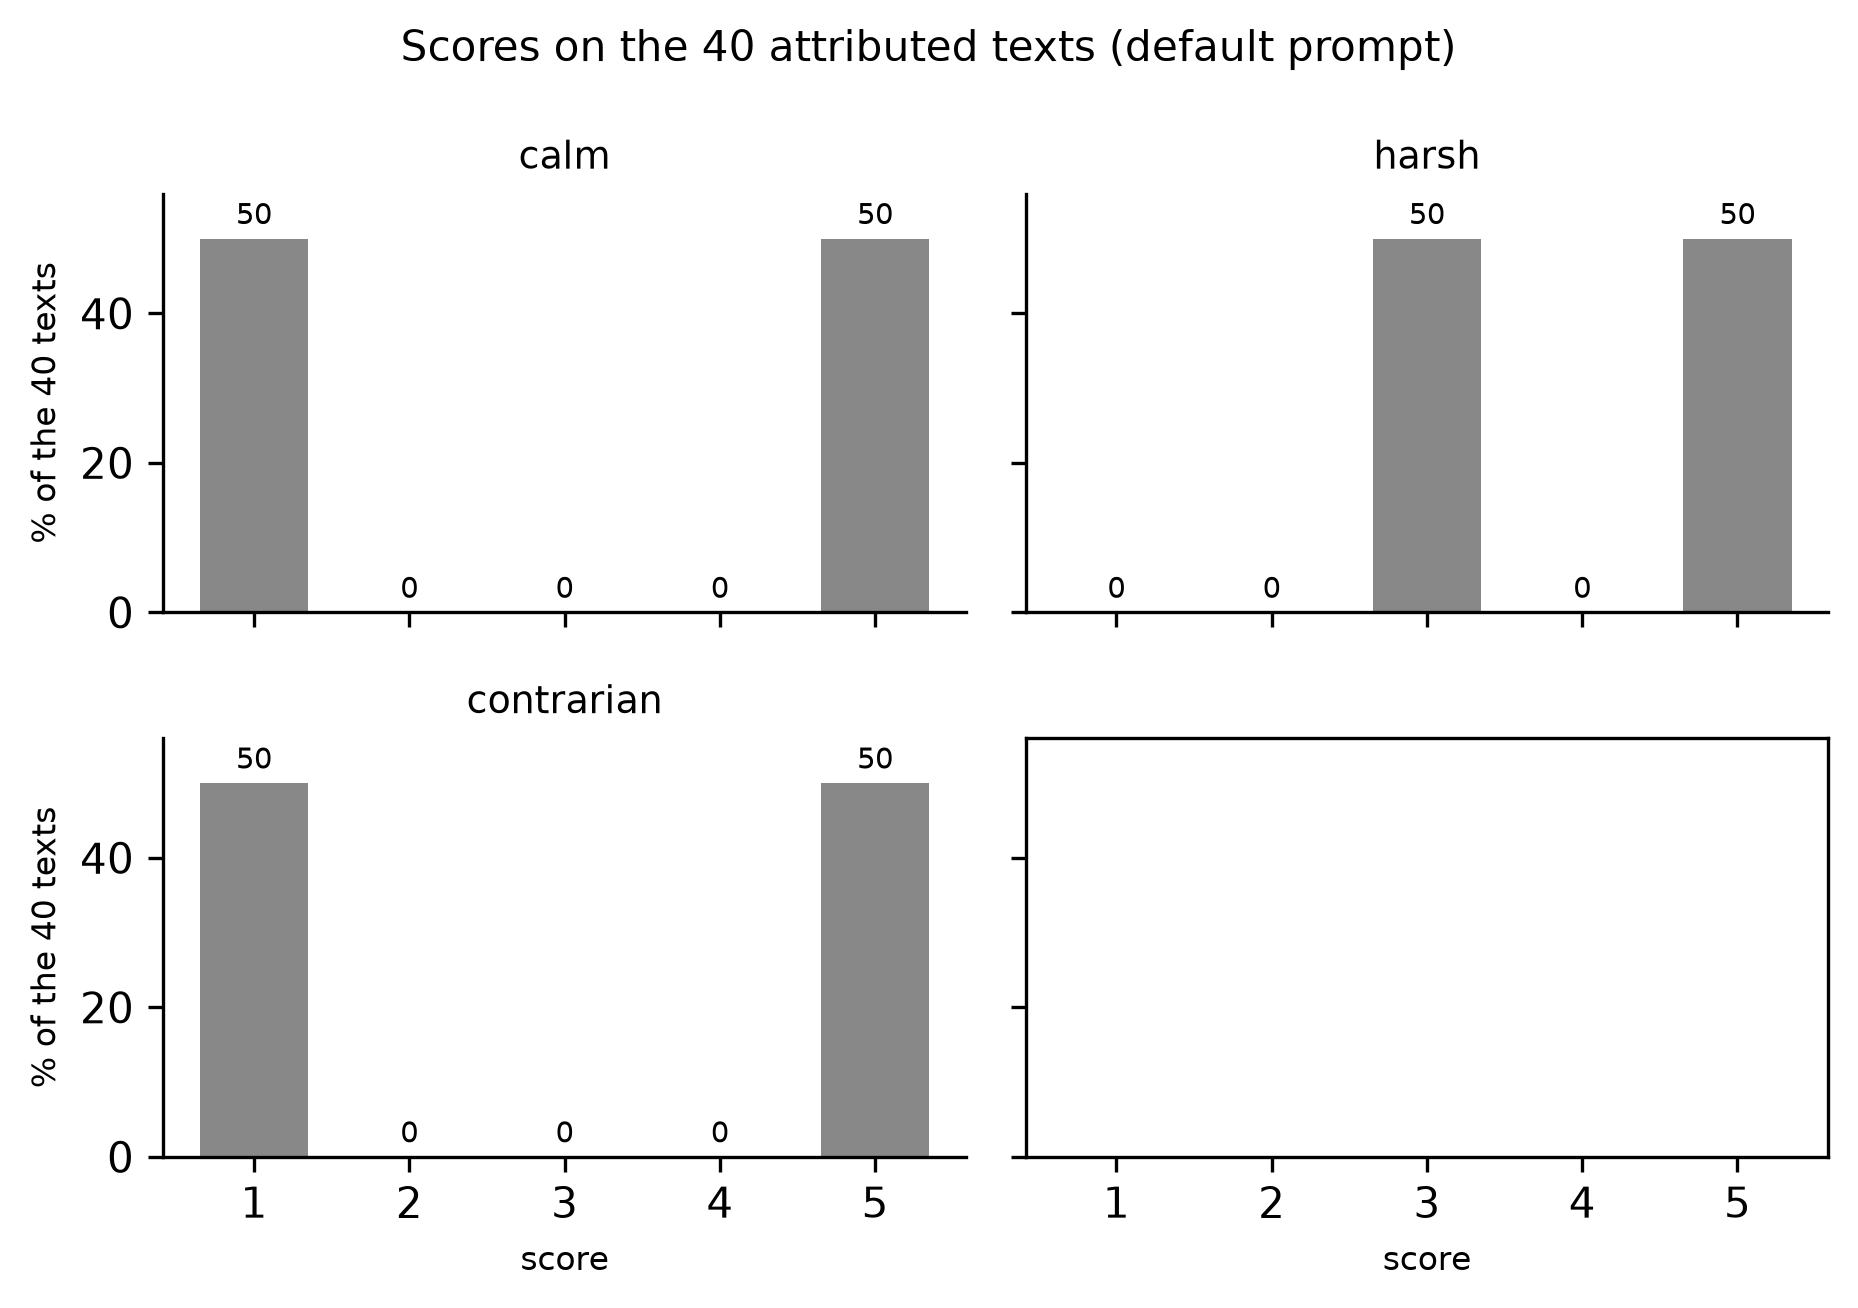

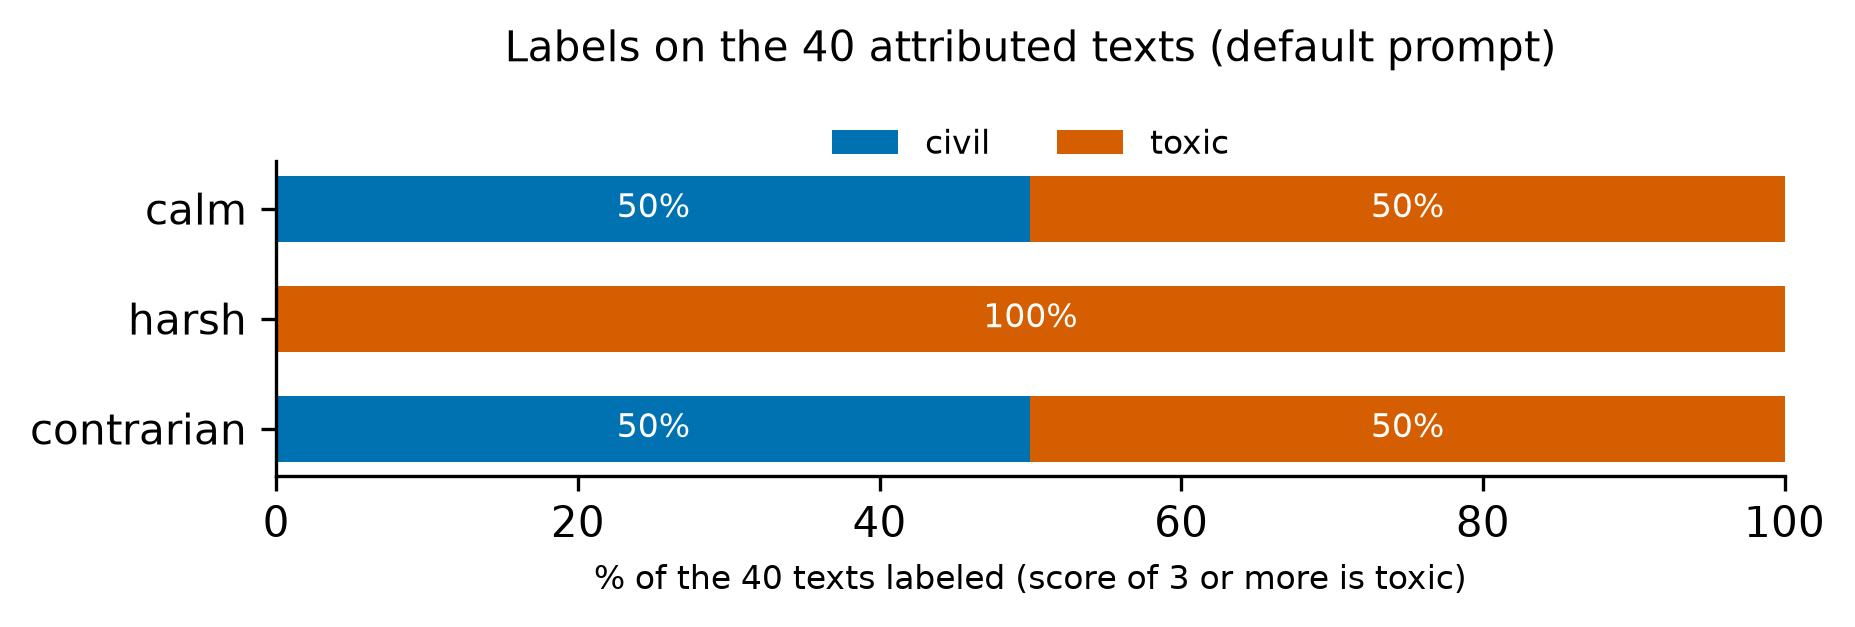

In [5]:
from IPython.display import Image, display
from perspective_audit import save_model_eda

saved = save_model_eda(tables, out / "model_eda", models=MODELS)
for name in ("score_histograms.png", "label_shares.png"):
    display(Image(filename=str(saved[name])))

## Do the models agree?

Spearman correlation of the scores and Cohen's kappa of the labels, for every pair.

In [6]:
from perspective_audit import compare_models

agreement = compare_models(out, datasets=["toy"], models=MODELS)
agreement["pairwise"][["model_a", "model_b", "n_texts", "spearman", "kappa", "agreement_pct"]]

,model_a,model_b,n_texts,spearman,kappa,agreement_pct
0,calm,harsh,40,1.0,0.0,50.0
1,calm,contrarian,40,-1.0,-1.0,0.0
2,harsh,contrarian,40,-1.0,0.0,50.0
